# Notebook 01 — Exploración inicial

**Maestría en Data Mining · FCEyN UBA · Taller de Tesis I · Grupo G2**

Carga los tres datasets del Stack Overflow Developer Survey (2023, 2024, 2025) y muestra
una exploración inicial: conteos, distribuciones de variables clave, construcción del
target binario y dinámica temporal de la brecha uso–confianza.

**Lógica:** importada de `scripts/pipeline.py`. Este notebook orquesta y visualiza.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Importar pipeline de scripts/pipeline
import importlib.util
spec = importlib.util.spec_from_file_location("pipeline", ROOT / "scripts" / "pipeline.py")
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
sns.set_theme(style="whitegrid")

print(f"ROOT = {ROOT}")
print(f"TARGET_LABELS = {pipeline.TARGET_LABELS}")

ROOT = /home/daro-m/Personal/maestria-taller-de-tesis-1
TARGET_LABELS = {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga y normalización de los 3 datasets

Llamamos a `pipeline.cargar_y_normalizar()` que aplica las normalizaciones necesarias:
- Aplana `AISelect` 2025 (3 niveles de Yes → "Yes")
- Corrige swap `AIBen` ↔ `AIAcc` en 2023
- Recodifica DevType 2025 (AI/ML engineer + Data engineer → DS/ML)

In [2]:
df23, df24, df25 = pipeline.cargar_y_normalizar()
print(f"\nShapes:")
print(f"  2023: {df23.shape}")
print(f"  2024: {df24.shape}")
print(f"  2025: {df25.shape}")

Cargados: 2023=89,184  2024=65,437  2025=49,191
DevType 2025 recodificado: 1447 respondientes en DS/ML (unión nueva)
✅ Schemas normalizados

Shapes:
  2023: (89184, 85)
  2024: (65437, 115)
  2025: (49191, 174)


## 3. Filtro: solo developers profesionales (`MainBranch`)

In [3]:
DEV_LABEL = pipeline.DEV_LABEL
filtros = pd.DataFrame({
    "Año": [2023, 2024, 2025],
    "Total respuestas": [len(df23), len(df24), len(df25)],
    "Devs profesionales": [
        (df23["MainBranch"] == DEV_LABEL).sum(),
        (df24["MainBranch"] == DEV_LABEL).sum(),
        (df25["MainBranch"] == DEV_LABEL).sum(),
    ],
})
filtros["% retenido"] = (filtros["Devs profesionales"] / filtros["Total respuestas"] * 100).round(1)
filtros

,Año,Total respuestas,Devs profesionales,% retenido
0,2023,89184,67237,75.4
1,2024,65437,50207,76.7
2,2025,49191,37467,76.2


## 4. Distribución del target binario antes de restringir

Construimos el target sobre cada dataset con la función `pipeline.construir_target`:

- `target = 1` ("Sin discrepancia"): `AISelect = Yes` AND `AISent ∈ {Favorable, Very favorable}`.
- `target = 0` ("Con discrepancia uso-actitud"): cualquier otro caso.

In [4]:
for df_y, year in [(df23, 2023), (df24, 2024), (df25, 2025)]:
    df_y["target"] = pipeline.construir_target(df_y)

df_full = pd.concat([df23, df24, df25], ignore_index=True)
df_full = df_full[df_full["MainBranch"] == DEV_LABEL].copy()

print(f"Devs profesionales totales (3 años): {len(df_full):,}\n")
print("Distribución target sobre dataset full (sin restringir a usuarios):")
print(df_full.groupby("survey_year")["target"].agg(["count", "sum", "mean"]).round(3))

Devs profesionales totales (3 años): 154,911

Distribución target sobre dataset full (sin restringir a usuarios):
             count    sum   mean
survey_year                     
2023         67237  25144  0.374
2024         50207  22695  0.452
2025         37467  15235  0.407


## 5. Brecha uso–confianza por año (componentes del target)

Replica intra-dataset la métrica reportada por Gillespie/KPMG (2025) a nivel poblacional.

In [5]:
brechas = []
for year, df_y in [(2023, df23), (2024, df24), (2025, df25)]:
    sub = df_y[df_y["MainBranch"] == DEV_LABEL]
    uso = (sub["AISelect"] == "Yes").mean() * 100
    confianza = sub["AISent"].isin(pipeline.ACTITUD_POSITIVA).mean() * 100
    brechas.append({
        "año": year, "% uso": round(uso, 1), "% confianza favorable": round(confianza, 1),
        "brecha (pp)": round(uso - confianza, 1)
    })
brechas_df = pd.DataFrame(brechas)
brechas_df

,año,% uso,% confianza favorable,brecha (pp)
0,2023,44.2,53.1,-9.0
1,2024,59.0,51.2,7.8
2,2025,56.1,42.2,13.9


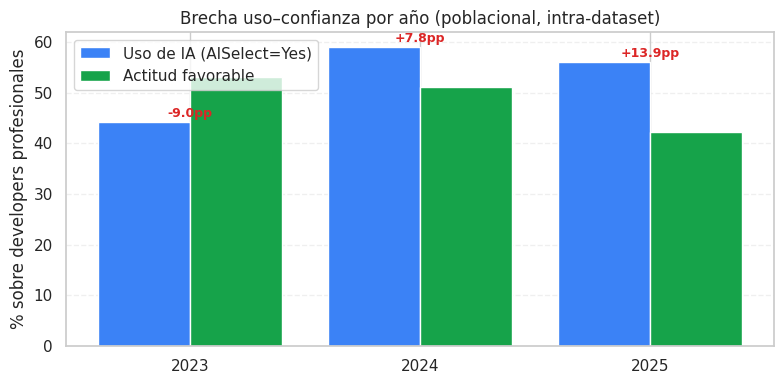

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
ax.bar(x - 0.2, brechas_df["% uso"], 0.4, label="Uso de IA (AISelect=Yes)", color="#3b82f6")
ax.bar(x + 0.2, brechas_df["% confianza favorable"], 0.4, label="Actitud favorable", color="#16a34a")
ax.set_xticks(x)
ax.set_xticklabels(["2023", "2024", "2025"])
ax.set_ylabel("% sobre developers profesionales")
ax.set_title("Brecha uso–confianza por año (poblacional, intra-dataset)")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
for i, row in brechas_df.iterrows():
    ax.text(i, row["% uso"] + 1, f"{row['brecha (pp)']:+.1f}pp", ha="center", fontsize=9, color="#dc2626", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura.** La brecha se invierte entre 2023 y 2024:
- 2023: confianza > uso (brecha negativa).
- 2024–2025: uso > confianza (brecha positiva creciente).

En 2 años el signo cambia y la magnitud llega a +14 pp en 2025. Es consistente con el fenómeno reportado por Gillespie/KPMG (66 % uso global / 46 % confianza, brecha +20 pp).

## 6. Distribuciones de variables clave del perfil profesional

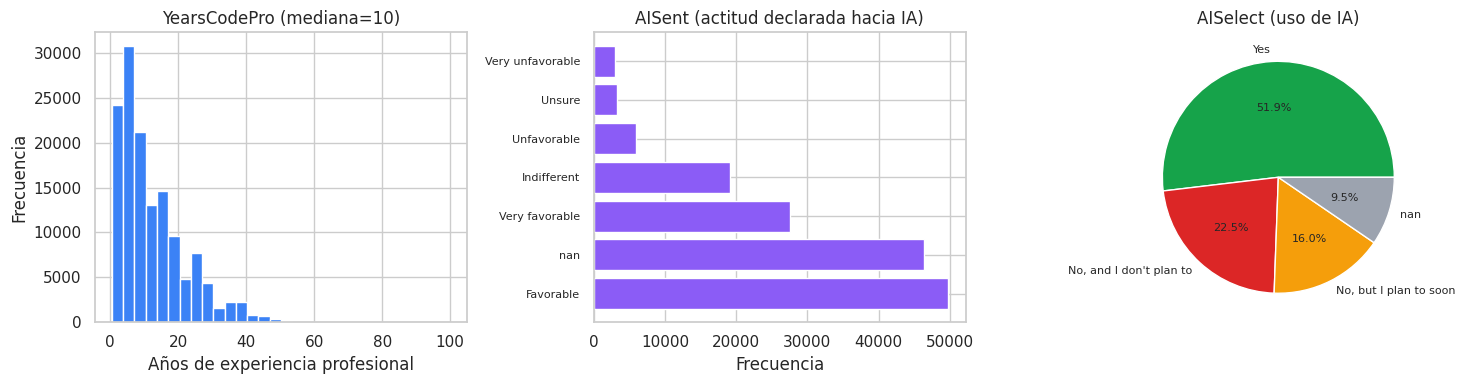

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# YearsCodePro
yearscodepro = df_full["YearsCodePro"].dropna()
yearscodepro_num = pd.to_numeric(yearscodepro.replace({"Less than 1 year": 0.5, "More than 50 years": 51}), errors="coerce").dropna()
axes[0].hist(yearscodepro_num, bins=30, color="#3b82f6", edgecolor="white")
axes[0].set_xlabel("Años de experiencia profesional")
axes[0].set_ylabel("Frecuencia")
axes[0].set_title(f"YearsCodePro (mediana={yearscodepro_num.median():.0f})")

# AISent distribución
sent_counts = df_full["AISent"].value_counts(dropna=False)
axes[1].barh(range(len(sent_counts)), sent_counts.values, color="#8b5cf6")
axes[1].set_yticks(range(len(sent_counts)))
axes[1].set_yticklabels([str(x)[:25] for x in sent_counts.index], fontsize=8)
axes[1].set_xlabel("Frecuencia")
axes[1].set_title("AISent (actitud declarada hacia IA)")

# AISelect distribución
sel_counts = df_full["AISelect"].value_counts(dropna=False)
axes[2].pie(sel_counts.values, labels=[str(x)[:25] for x in sel_counts.index],
            autopct="%1.1f%%", colors=["#16a34a", "#dc2626", "#f59e0b", "#9ca3af"][:len(sel_counts)],
            textprops={"fontsize": 8})
axes[2].set_title("AISelect (uso de IA)")

plt.tight_layout()
plt.show()

## 7. Próximo paso

`notebooks/02_preprocesamiento.ipynb` ejecuta el pipeline completo (limpieza, encoding, OHE, binarización) y genera los dos artefactos parquet:
- `data/df_clean.parquet` — dataset full (155k × 124 cols)
- `data/df_clean_users.parquet` — dataset restringido a usuarios activos (~80k × 124 cols)